# 01 Data Exploration
We explore the course version of the ART dataset (`amarfurt/art-nlp-hs26`): split sizes, label distribution and text lengths.


Load the train, validation and test splits (like on slide 9 of the course project slides).

In [10]:
from datasets import load_dataset

train = load_dataset("amarfurt/art-nlp-hs26", split="train")
valid = load_dataset("amarfurt/art-nlp-hs26", split="validation")
test = load_dataset("amarfurt/art-nlp-hs26", split="test")

print(len(train), len(valid), len(test))


16801 1000 1532


Look at the structure of the dataset: columns, data types and the first examples.

In [15]:
print(train)
print()
print(train.features)
print()
print(train[:2])


Dataset({
    features: ['observation_1', 'observation_2', 'hypothesis_1', 'hypothesis_2', 'label'],
    num_rows: 16801
})

{'observation_1': Value('string'), 'observation_2': Value('string'), 'hypothesis_1': Value('string'), 'hypothesis_2': Value('string'), 'label': ClassLabel(names=['0', '1', '2'])}

{'observation_1': ['A baby panda was lost in the woods.', 'A bank teller told me to rob the bank where she worked.'], 'observation_2': ['He was reunited with his parents, who also lived at the zoo.', 'We split the money equally.'], 'hypothesis_1': ['He was never lost.', 'The mountain told me when no one would be there.'], 'hypothesis_2': ['All the people from the zoo looked for him.', 'The teller told me when no one would be there.'], 'label': [2, 2]}


Look at one example and count how often each label occurs in each split.

In [11]:
import nltk

print(train[0])
print()
print('train:', nltk.FreqDist(train['label']).most_common())
print('valid:', nltk.FreqDist(valid['label']).most_common())
print('test: ', nltk.FreqDist(test['label']).most_common())



{'observation_1': 'A baby panda was lost in the woods.', 'observation_2': 'He was reunited with his parents, who also lived at the zoo.', 'hypothesis_1': 'He was never lost.', 'hypothesis_2': 'All the people from the zoo looked for him.', 'label': 2}

train: [(1, 8461), (2, 8340)]
valid: [(1, 508), (2, 492)]
test:  [(1, 781), (2, 751)]


The labels are balanced (about 50/50) in all splits. Accuracy can be used, and always predicting the majority label gives about 51%, which is the baseline our models have to beat.

Compute the average and maximum number of words per text in the training set. For this first look, we split at whitespace; proper tokenization follows in preprocessing.

In [12]:
for column in ["observation_1", "observation_2", "hypothesis_1", "hypothesis_2"]:
    lengths = [len(text.split()) for text in train[column]]
    print(f"{column}: mean {sum(lengths) / len(lengths):.1f}, max {max(lengths)} words")


observation_1: mean 8.1, max 16 words
observation_2: mean 9.3, max 19 words
hypothesis_1: mean 8.4, max 30 words
hypothesis_2: mean 8.4, max 30 words


Plot the distribution of text lengths for each of the four text fields.

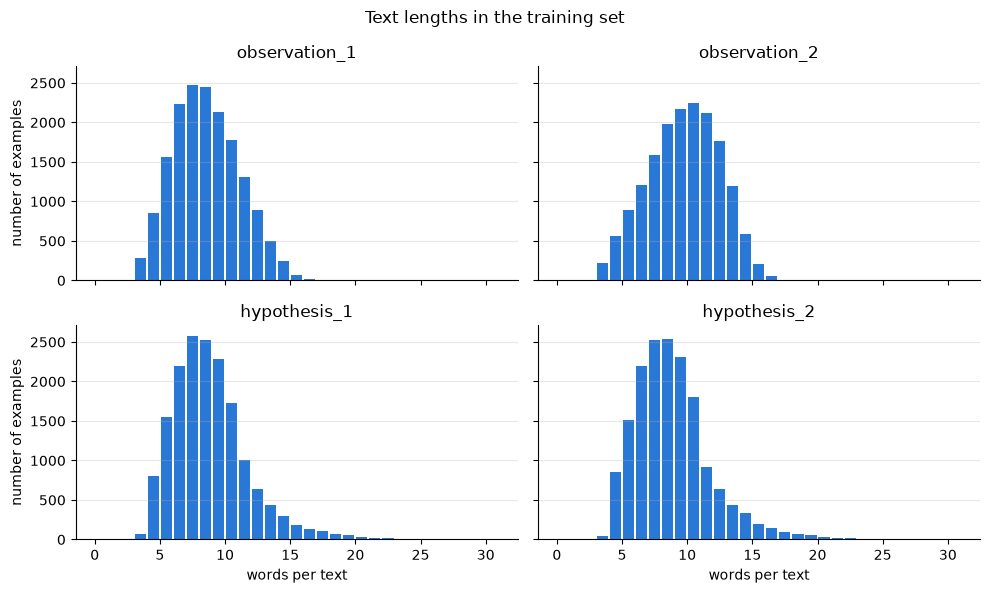

In [13]:
import matplotlib.pyplot as plt

columns = ["observation_1", "observation_2", "hypothesis_1", "hypothesis_2"]

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True)

for ax, column in zip(axes.flat, columns):
    lengths = [len(text.split()) for text in train[column]]
    ax.hist(lengths, bins=range(0, 32), color="#2a78d6", rwidth=0.85)
    ax.set_title(column)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)

for ax in axes[1]:
    ax.set_xlabel("words per text")
for ax in axes[:, 0]:
    ax.set_ylabel("number of examples")

fig.suptitle("Text lengths in the training set")
fig.tight_layout()
plt.show()


All texts are short (about 8–9 words on average). The observations end at about 19 words, while the hypotheses have a long tail up to 30 words. Both hypotheses have the same length distribution, so the length gives no hint which one is correct.


The lengths above are almost identical for both hypotheses. But how similar are their words? 
Count how many words differ between the two hypotheses of each example. In ART, the wrong hypothesis was created by editing a few words of a correct one (Bhagavatula et al., 2020).

In [14]:
differences = []
for h1, h2 in zip(train['hypothesis_1'], train['hypothesis_2']):
    words_1 = set(h1.lower().split())
    words_2 = set(h2.lower().split())
    differences.append(len(words_1 ^ words_2))  # words that occur in only one of the two hypotheses

fdist = nltk.FreqDist(differences)
print(f'Mean number of differing words: {sum(differences) / len(differences):.1f}')
print(f'At most 5 differing words: {sum(d <= 5 for d in differences) / len(differences):.2%}')
print(fdist.most_common(10))

Mean number of differing words: 5.1
At most 5 differing words: 67.03%
[(2, 4699), (4, 2497), (3, 1968), (5, 1578), (6, 1371), (7, 874), (8, 699), (9, 502), (1, 413), (10, 409)]


In two thirds of the examples, the hypotheses differ by at most 5 words, most often by a single replaced word, so the difference is easy to lose when word vectors are averaged.

## Sources
- Dataset: course version of ART, `amarfurt/art-nlp-hs26` on Hugging Face (A. Marfurt), based on Bhagavatula et al. (2020), *Abductive Commonsense Reasoning*, ICLR 2020, https://arxiv.org/abs/1908.05739, which builds on ROCStories (Mostafazadeh et al., 2016).
- Loading the splits: code from slide 9 of the course slides "Course Project HS26" (A. Marfurt).
- Counting with `nltk.FreqDist`: as in the course exercise "NLP Pipeline" (Week 1).
- Text length histogram: matplotlib, as used for plots in the course exercise "Word Embeddings" (Week 2); code written with the help of Claude.
- Hypothesis comparison: idea from Bhagavatula et al. (2020) and slide 7 of "Course Project HS26" (the wrong hypothesis was created by editing up to 5 words of a correct one); code written with the help of Claude.
- Tools: code written with the help of Claude (Anthropic); all code reviewed and understood by me.